# Day 49: Python capstone: QuickBite orders

UrbanKart Data Analyst Training. QuickBite is a fictional cloud-kitchen chain with 8 kitchens in 4 cities. Put the 9 monthly CSV files and quickbite_platforms.csv in the same folder as this notebook. Run the cells in order: each step builds on the previous one.

**Example.** List the 9 monthly order files with glob and look at the first rows of June.

In [1]:
import glob
import pandas as pd
import matplotlib.pyplot as plt
files = sorted(glob.glob('quickbite_orders_2026_*.csv'))
print(len(files), files[0], files[-1])
pd.read_csv(files[5]).head(4)

9 quickbite_orders_2026_01.csv quickbite_orders_2026_09.csv


   order_id   order_date order_time      kitchen       city      platform      category  items Order Amount  discount_pct  delivery_mins  rating     status
0  QB113947   19-06-2026      14:24  Indiranagar  Bengaluru  Aggregator A       Biryani      2         ₹718             0           47.0     NaN  Delivered
1  QB114677  27 Jun 2026      13:01      Andheri     Mumbai  Aggregator A     Beverages      1         ₹109            10           42.0     4.0  delivered
2  QB114075   20-06-2026      18:24      Andheri     Mumbai  Aggregator A       Biryani      3          977             0            NaN     NaN  Cancelled
3  QB113606   15-06-2026      19:38  Indiranagar  Bengaluru  Aggregator A  North Indian      2         ₹558            10           33.0     5.0  Delivered

**T1.** Read all files in a loop, standardise column names (lowercase, underscores, amount), and combine them with concat. How many rows?

In [2]:
frames = []
for f in files:
    t = pd.read_csv(f)
    t.columns = t.columns.str.strip().str.lower().str.replace(' ', '_')
    t = t.rename(columns={'order_amount': 'amount'})
    t['source_file'] = f
    frames.append(t)
raw = pd.concat(frames, ignore_index=True)
print(raw.shape)
raw.columns.tolist()

(24355, 14)


['order_id', 'order_date', 'order_time', 'kitchen', 'city', 'platform', 'category', 'items', 'amount', 'discount_pct', 'delivery_mins', 'rating', 'status', 'source_file']

**T2.** Remove exact duplicate rows. How many were removed? Is order_id now unique?

In [3]:
before = len(raw)
df = raw.drop_duplicates(subset=[c for c in raw.columns if c != 'source_file']).copy()
print(before - len(df), len(df), df['order_id'].is_unique)

355 24000 True


**T3.** Convert order_date (three different formats) to datetime, one format at a time. Any failures? Date range? Does every date match its file month?

In [4]:
raw_dates = df['order_date']
d1 = pd.to_datetime(raw_dates, format='%d-%m-%Y', errors='coerce')
d2 = pd.to_datetime(raw_dates, format='%Y/%m/%d', errors='coerce')
d3 = pd.to_datetime(raw_dates, format='%d %b %Y', errors='coerce')
df['order_date'] = d1.fillna(d2).fillna(d3)
file_month = df['source_file'].str[-6:-4].astype(int)
print(df['order_date'].isna().sum(), df['order_date'].min().date(), df['order_date'].max().date())
print((df['order_date'].dt.month != file_month).sum())

0 2026-01-01 2026-09-30
0


**T4.** Clean amount: remove '₹' and commas, convert to numbers ('NA' → missing). How many missing?

In [5]:
df['amount'] = pd.to_numeric(df['amount'].astype(str).str.replace('₹', '').str.replace(',', ''), errors='coerce')
print(df['amount'].isna().sum(), df['amount'].describe().round(0).to_dict())

700 {'count': 23300.0, 'mean': 440.0, 'std': 297.0, 'min': 59.0, '25%': 229.0, '50%': 349.0, '75%': 588.0, 'max': 1676.0}


**T5.** Clean kitchen names and status values. How many distinct kitchens and statuses after cleaning?

In [6]:
fix = {'Kormangala': 'Koramangala', 'Hsr': 'HSR Layout', 'Hsr Layout': 'HSR Layout', 'Indira Nagar': 'Indiranagar',
       'Andheri West': 'Andheri', 'Vimannagar': 'Viman Nagar'}
df['kitchen'] = df['kitchen'].str.strip().str.title().replace(fix)
df['status'] = df['status'].str.strip().str.title()
print(df['kitchen'].nunique(), sorted(df['kitchen'].unique()))
df['status'].value_counts()

8 ['Andheri', 'Gachibowli', 'HSR Layout', 'Indiranagar', 'Koramangala', 'Madhapur', 'Powai', 'Viman Nagar']


status
Delivered    22653
Cancelled     1347

**T6.** Missing-value check. Drop orders with missing amount, and confirm delivery_mins is missing only for cancelled orders.

In [7]:
print(df.isna().sum()[lambda s: s > 0].to_dict())
df = df.dropna(subset=['amount'])
print(len(df), df.loc[df['delivery_mins'].isna(), 'status'].value_counts().to_dict())

{'amount': 700, 'delivery_mins': 1347, 'rating': 9975}
23300 {'Cancelled': 1314}


**T7.** Delivered revenue by month (₹ lakh) and a line chart.

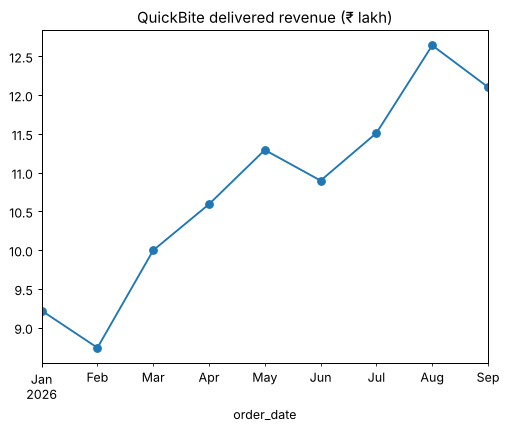

[9.22, 8.74, 10.0, 10.59, 11.29, 10.9, 11.51, 12.64, 12.1]


In [8]:
dl = df[df['status'] == 'Delivered'].copy()
monthly = dl.groupby(dl['order_date'].dt.to_period('M'))['amount'].sum() / 1e5
print(monthly.round(2).tolist())
monthly.plot(marker='o', title='QuickBite delivered revenue (₹ lakh)')
plt.show()

**T8.** Kitchen scorecard: revenue (₹ lakh), orders, cancellation %, average rating and delivery minutes.

In [9]:
k = df.groupby('kitchen').agg(orders=('order_id', 'count'),
                              cancel_pct=('status', lambda s: (s == 'Cancelled').mean() * 100))
k = k.join(dl.groupby('kitchen').agg(revenue_lakh=('amount', lambda a: a.sum() / 1e5),
                                     rating=('rating', 'mean'), mins=('delivery_mins', 'mean')))
k.round(2).sort_values('revenue_lakh', ascending=False)

             orders  cancel_pct  revenue_lakh  rating   mins
kitchen                                                     
Koramangala    3879        5.00         16.48    4.32  34.24
Andheri        3665        6.60         15.14    4.07  41.13
Indiranagar    3367        5.17         14.04    4.29  34.30
Gachibowli     3011        5.55         12.43    4.30  34.28
HSR Layout     2701        5.07         11.32    4.30  34.17
Powai          2569        5.25         10.75    4.33  34.35
Viman Nagar    2391        4.98          9.77    4.32  34.45
Madhapur       1717        8.50          7.08    4.06  41.05

**T9.** Platforms: merge commission rates; gross revenue, net revenue after discount and commission, and net as % of gross.

In [10]:
plat = pd.read_csv('quickbite_platforms.csv')
dl = dl.merge(plat, on='platform', how='left')
dl['net'] = dl['amount'] * (1 - dl['discount_pct'] / 100) * (1 - dl['commission_pct'] / 100)
p = dl.groupby('platform')[['amount', 'net']].sum() / 1e5
p['net_pct'] = (p['net'] / p['amount'] * 100).round(1)
p.round(2)

              amount    net  net_pct
platform                            
Aggregator A   39.12  27.51     70.3
Aggregator B   26.37  19.48     73.9
Own App        31.52  30.36     96.3

**T10.** Does delivery time affect ratings? Average rating by delivery-time band, with a bar chart.

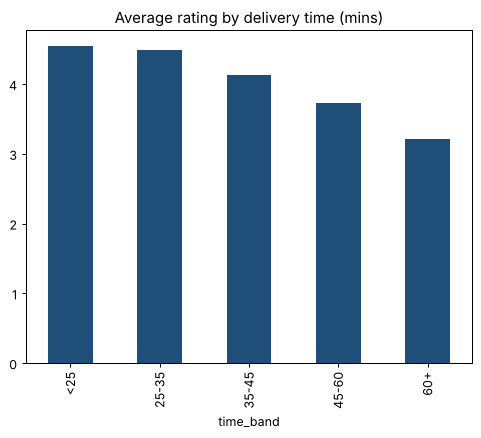

           mean  count
time_band             
<25        4.54   1716
25-35      4.49   4954
35-45      4.13   5027
45-60      3.72   1870
60+        3.21     39


In [11]:
dl['time_band'] = pd.cut(dl['delivery_mins'], bins=[0, 25, 35, 45, 60, 200], labels=['<25', '25-35', '35-45', '45-60', '60+'])
rb = dl.groupby('time_band', observed=True)['rating'].agg(['mean', 'count']).round(2)
print(rb)
rb['mean'].plot(kind='bar', title='Average rating by delivery time (mins)', color='#1f4e79')
plt.show()

**T11.** Orders by hour of the day: which hours are the peaks? Bar chart.

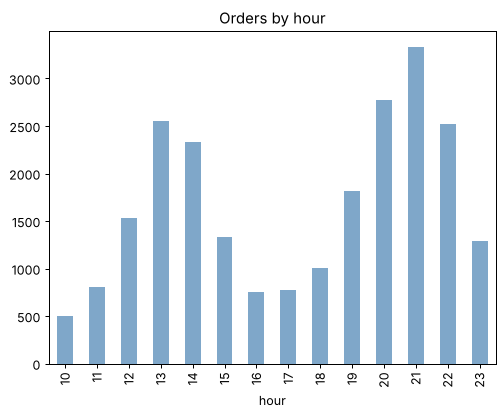

{21: 3333, 20: 2770, 13: 2548}


In [12]:
df['hour'] = df['order_time'].str[:2].astype(int)
h = df['hour'].value_counts().sort_index()
print(h.nlargest(3).to_dict())
h.plot(kind='bar', title='Orders by hour', color='#7fa7c9')
plt.show()

**T12.** Save the clean data and a summary workbook (kitchens, platforms, monthly) to Excel.

In [13]:
df.drop(columns='source_file').to_csv('quickbite_clean.csv', index=False)
with pd.ExcelWriter('quickbite_summary.xlsx') as xw:
    k.round(2).to_excel(xw, sheet_name='Kitchens')
    p.round(2).to_excel(xw, sheet_name='Platforms')
    monthly.round(2).to_frame('revenue_lakh').to_excel(xw, sheet_name='Monthly')
print('saved', len(df))

saved 23300
